# AI 그림과 실제 사진 구별하기

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras

# 데이터 가져오기
- Kaggle의 CIFAKE 데이터셋
- https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images

In [25]:
import kagglehub

path = kagglehub.dataset_download(
    "birdy654/cifake-real-and-ai-generated-synthetic-images"
)

100%|██████████| 105M/105M [00:06<00:00, 17.4MB/s]

Extracting files...


In [26]:
# test_ds.class_indices
class_names = ['FAKE', 'REAL']

# 데이터 불러오기
- 학습 데이터 갯수: 100K
- 테스트 데이터 갯수: 20K

In [27]:
train_dir = f'{path}/train'
test_dir = f'{path}/test'

In [28]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BATCH_SIZE = 16
IMAGE_SIZE = (32, 32)

train_gen = ImageDataGenerator(rescale=1./255.)

train_ds = train_gen.flow_from_directory(
    train_dir,
    batch_size=BATCH_SIZE,
    target_size=IMAGE_SIZE,
    class_mode='binary')

Found 100000 images belonging to 2 classes.


In [29]:
test_gen = ImageDataGenerator(rescale=1./255.)

test_ds = test_gen.flow_from_directory(
    test_dir,
    batch_size=BATCH_SIZE,
    target_size=IMAGE_SIZE,
    class_mode='binary',
    shuffle=False)

Found 20000 images belonging to 2 classes.


In [30]:
test_ds.class_indices

{'FAKE': 0, 'REAL': 1}

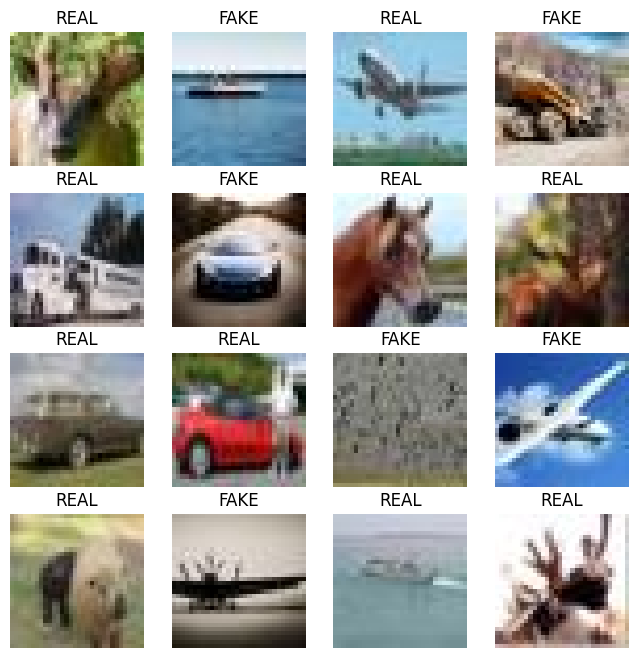

In [31]:
samples = train_ds[0]

plt.figure(figsize=(8, 8))
for i in range(BATCH_SIZE):
    plt.subplot(4, 4, i+1)
    plt.imshow(samples[0][i])
    plt.axis('off')
    plt.title(class_names[int(samples[1][i])])

plt.show()

# 모델 구성
- 합성곱 신경망

In [32]:
from keras.layers import Dense, Flatten, Conv2D, MaxPool2D
from keras import Sequential

kernel_size = (3, 3)

model = Sequential([
    Conv2D(32, kernel_size, activation='relu', input_shape=(32, 32, 3)),
    MaxPool2D(),
    Conv2D(64, kernel_size, activation='relu'),
    MaxPool2D(),
    Conv2D(128, kernel_size, activation='relu'),
    Flatten(),
    Dense(256, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer = 'adam',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 618,049 (2.36 MB)

 Trainable params: 618,049 (2.36 MB)

 Non-trainable params: 0 (0.00 B)

# 학습
- accuracy: 96%
- val_accuracy: 93%

In [33]:
from keras.callbacks import ModelCheckpoint

callbacks = [
    ModelCheckpoint(
        filepath='best_model.h5',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max')
]

In [34]:
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=test_ds,
    verbose=1,
    callbacks=callbacks
)

Epoch 1/10
6247/6250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8228 - loss: 0.3881

6250/6250 ━━━━━━━━━━━━━━━━━━━━ 67s 10ms/step - accuracy: 0.8647 - loss: 0.3146 - val_accuracy: 0.8894 - val_loss: 0.2627
Epoch 2/10
6247/6250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9073 - loss: 0.2289

6250/6250 ━━━━━━━━━━━━━━━━━━━━ 64s 10ms/step - accuracy: 0.9112 - loss: 0.2206 - val_accuracy: 0.9158 - val_loss: 0.2078
Epoch 3/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 62s 10ms/step - accuracy: 0.9238 - loss: 0.1928 - val_accuracy: 0.9096 - val_loss: 0.2212
Epoch 4/10
6246/6250 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9330 - loss: 0.1693

6250/6250 ━━━━━━━━━━━━━━━━━━━━ 63s 10ms/step - accuracy: 0.9328 - loss: 0.1697 - val_accuracy: 0.9262 - val_loss: 0.1826
Epoch 5/10
6245/6250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9404 - loss: 0.1526

6250/6250 ━━━━━━━━━━━━━━━━━━━━ 64s 10ms/step - accuracy: 0.9397 - loss: 0.1539 - val_accuracy: 0.9276 - val_loss: 0.1837
Epoch 6/10
6249/6250 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9477 - loss: 0.1370

6250/6250 ━━━━━━━━━━━━━━━━━━━━ 65s 10ms/step - accuracy: 0.9453 - loss: 0.1403 - val_accuracy: 0.9338 - val_loss: 0.1755
Epoch 7/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 63s 10ms/step - accuracy: 0.9514 - loss: 0.1266 - val_accuracy: 0.9326 - val_loss: 0.1744
Epoch 8/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 63s 10ms/step - accuracy: 0.9552 - loss: 0.1146 - val_accuracy: 0.9283 - val_loss: 0.1955
Epoch 9/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 65s 10ms/step - accuracy: 0.9603 - loss: 0.1035 - val_accuracy: 0.9212 - val_loss: 0.2376
Epoch 10/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 65s 10ms/step - accuracy: 0.9636 - loss: 0.0930 - val_accuracy: 0.9292 - val_loss: 0.2234


# 학습 과정 시각화

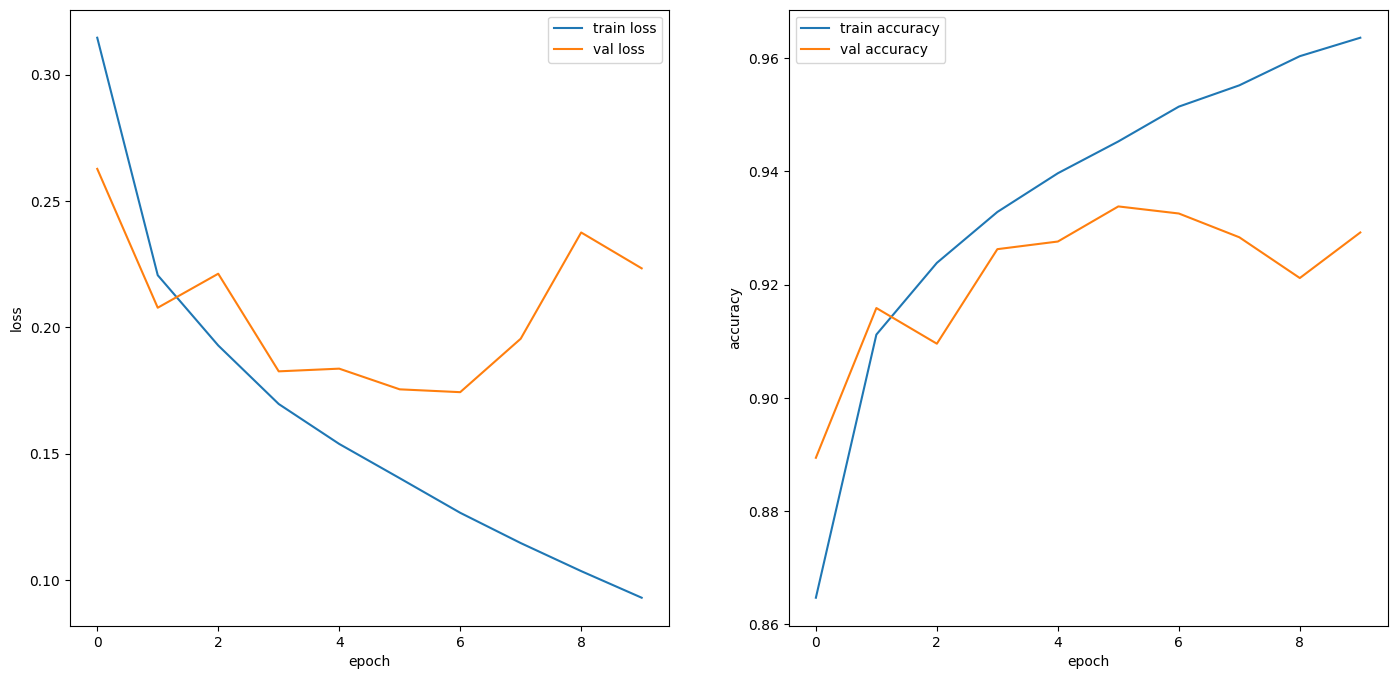

In [35]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure(figsize=(17, 8))

    plt.subplot(1, 2, 1)
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.plot(hist['epoch'], hist['loss'], label='train loss')
    plt.plot(hist['epoch'], hist['val_loss'], label='val loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.plot(hist['epoch'], hist['accuracy'], label='train accuracy')
    plt.plot(hist['epoch'], hist['val_accuracy'], label='val accuracy')
    plt.legend()
    plt.show()

plot_history(history)

# 검증

In [36]:
y_pred = model.predict(test_ds)

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step


In [37]:
y_pred_s = (y_pred > 0.5).astype('int').flatten()
y_pred_s

array([0, 0, 0, ..., 1, 1, 0], shape=(20000,))

In [38]:
test_ds.classes

array([0, 0, 0, ..., 1, 1, 1], shape=(20000,), dtype=int32)

# metrics

In [39]:
from sklearn.metrics import classification_report


print(classification_report(test_ds.classes, y_pred_s))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93     10000
           1       0.94      0.91      0.93     10000

    accuracy                           0.93     20000
   macro avg       0.93      0.93      0.93     20000
weighted avg       0.93      0.93      0.93     20000



# confusion matrix

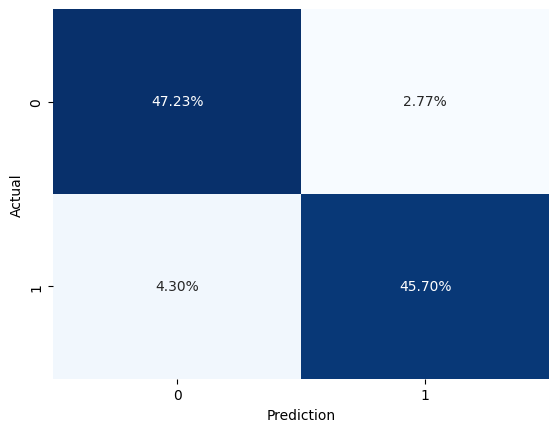

In [40]:
from sklearn.metrics import confusion_matrix

def show_cfm(y_test, y_pred):
    cfm = confusion_matrix(y_test, y_pred).astype('float')
    cfm /= cfm.sum().sum()
    s = sns.heatmap(cfm, annot=True, cmap='Blues', fmt='.2%', cbar=False)
    s.set(xlabel='Prediction', ylabel='Actual')
    plt.show()

show_cfm(test_ds.classes, y_pred_s)

# 시연

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step
[[0.48586032]]


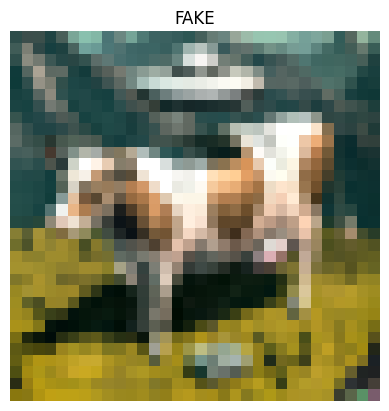

In [41]:
from PIL import Image
from urllib.request import urlretrieve
import numpy as np

# 시연 시, 확인
test_file = "fake.jpg"
urlretrieve("https://raw.githubusercontent.com/plming/cifake-classifier-demo/HEAD/samples/fake.jpg", test_file)

image = Image.open(test_file).convert('RGB')
image = image.resize(IMAGE_SIZE)

# 이미지를 numpy 배열로 변환
image_array = np.array(image)
image_array = image_array / 255
image_array = image_array.reshape(-1, 32, 32, 3)

y_pred = model.predict(image_array)
print(y_pred)

plt.imshow(image)
plt.axis(False)

plt.title(class_names[int(y_pred.item() > 0.5)])
plt.show()

In [42]:
model.save("model.h5")

In [43]:
from keras.models import load_model

loaded_model = load_model('model.h5')
loaded_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 618,051 (2.36 MB)

 Trainable params: 618,049 (2.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)